In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [14]:
df=pd.read_csv('/content/diabetes_prediction_dataset.csv')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [16]:
df.shape

(100000, 9)

In [17]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [18]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [19]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [20]:
df.duplicated().sum()

np.int64(3854)

In [21]:
df=df.drop_duplicates()

In [22]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


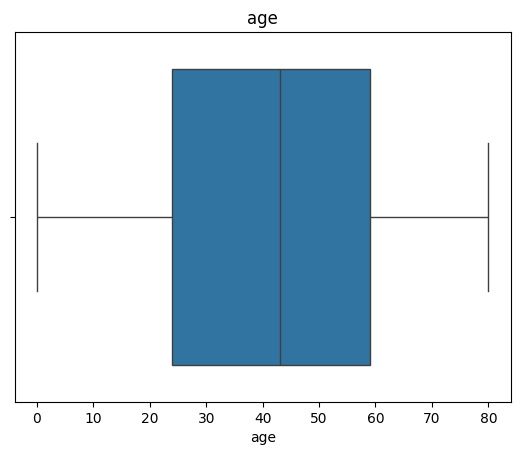

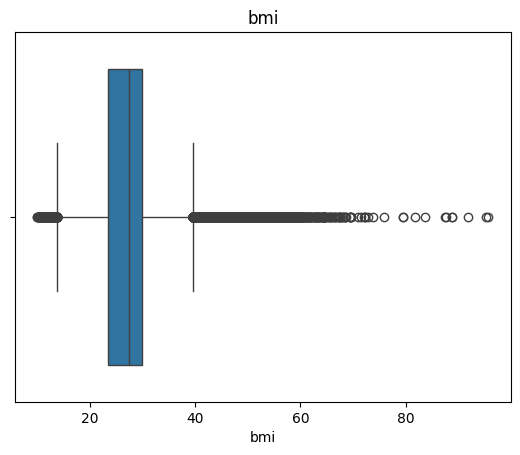

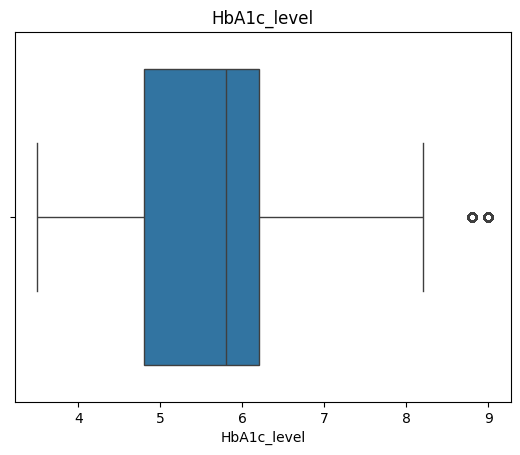

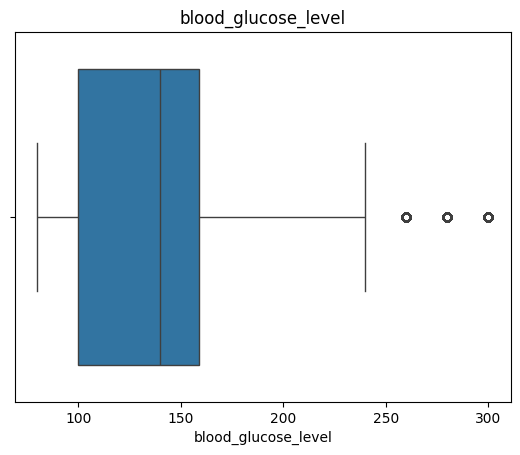

In [23]:
numeric_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [24]:
x=df.drop(columns='diabetes')

In [25]:
y=df['diabetes']

In [26]:
x_encoded = pd.get_dummies(x, columns=['gender','smoking_history'], drop_first=True,dtype=int)

In [27]:
x_encoded

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,0,0,0,0,1,0
1,54.0,0,0,27.32,6.6,80,0,0,0,0,0,0,0
2,28.0,0,0,27.32,5.7,158,1,0,0,0,0,1,0
3,36.0,0,0,23.45,5.0,155,0,0,1,0,0,0,0
4,76.0,1,1,20.14,4.8,155,1,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99994,36.0,0,0,24.60,4.8,145,0,0,0,0,0,0,0
99996,2.0,0,0,17.37,6.5,100,0,0,0,0,0,0,0
99997,66.0,0,0,27.83,5.7,155,1,0,0,0,1,0,0
99998,24.0,0,0,35.42,4.0,100,0,0,0,0,0,1,0


In [28]:
from sklearn.model_selection import train_test_split

In [29]:
x_train,x_test,y_train,y_test=train_test_split(x_encoded,y,test_size=0.2,random_state=42)

In [30]:
x_train.shape

(76916, 13)

In [31]:
y_train.shape

(76916,)

In [32]:
from sklearn.preprocessing import StandardScaler
SS=StandardScaler()

In [33]:
x_train=SS.fit_transform(x_train)
x_test=SS.transform(x_test)

In [34]:
from sklearn.linear_model import LogisticRegression
LR=LogisticRegression()
LR.fit(x_train,y_train)


LogisticRegression()

In [35]:
y_pred=LR.predict(x_test)

In [36]:
y_pred

array([0, 0, 1, ..., 0, 0, 0])

In [37]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,f1_score,classification_report

In [38]:
accuracy_score(y_test,y_pred)

0.9570982839313572

In [39]:
print(confusion_matrix(y_test,y_pred))

[[17325   184]
 [  641  1080]]


In [40]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17509
           1       0.85      0.63      0.72      1721

    accuracy                           0.96     19230
   macro avg       0.91      0.81      0.85     19230
weighted avg       0.95      0.96      0.95     19230



In [41]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=3)

In [42]:
knn.fit(x_train,y_train)
knn.predict(x_test)
knn.score(x_test,y_test)

0.9558502340093604

In [43]:
y_pred_knn=knn.predict(x_test)

In [44]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,f1_score,classification_report

In [45]:
accuracy_score(y_test,y_pred_knn)

0.9558502340093604

In [46]:
print(confusion_matrix(y_test,y_pred_knn))

[[17282   227]
 [  622  1099]]


In [47]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17509
           1       0.83      0.64      0.72      1721

    accuracy                           0.96     19230
   macro avg       0.90      0.81      0.85     19230
weighted avg       0.95      0.96      0.95     19230



In [48]:
from sklearn.tree import DecisionTreeClassifier

In [49]:
DT=DecisionTreeClassifier()
DT.fit(x_train,y_train)
y_pred_DT=DT.predict(x_test)

In [50]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,f1_score,classification_report

In [51]:
accuracy_score(y_test,y_pred_DT)

0.9482059282371295

In [52]:
print(confusion_matrix(y_test,y_pred_DT))

[[16963   546]
 [  450  1271]]


In [53]:
print(classification_report(y_test,y_pred_DT))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97     17509
           1       0.70      0.74      0.72      1721

    accuracy                           0.95     19230
   macro avg       0.84      0.85      0.84     19230
weighted avg       0.95      0.95      0.95     19230



Three classification models—Logistic Regression, K-Nearest Neighbors (KNN), and Decision Tree—were developed to predict diabetes. Logistic Regression achieved the highest accuracy of 95.71% and precision of 85%, with 63% recall and an F1-score of 72%. KNN achieved 95.59% accuracy, 83% precision, 64% recall, and 72% F1-score. Decision Tree achieved 94.77% accuracy, 70% precision, 74% recall, and 72% F1-score. Overall, Logistic Regression was selected as the best-performing model because it achieved the highest accuracy and precision while maintaining the same F1-score as the other models. However, the Decision Tree achieved the highest recall and missed fewer diabetic cases, making it preferable if identifying as many actual diabetic patients as possible is the main priority.